# Maintenance prédictive et Machine Learning explicable

## Contexte

Les entreprises industrielles subissent des pannes d'équipement non planifiées qui immobilisent leurs lignes de production. Deux postes de coûts en découlent : la perte de production pendant l'immobilisation, et le surcoût d'une intervention en urgence par rapport à une maintenance planifiée.

Anticiper ces pannes permettrait de planifier les interventions. La difficulté tient à l'arbitrage : intervenir trop tôt conduit à remplacer des pièces encore fonctionnelles et à immobiliser la machine inutilement ; intervenir trop tard laisse survenir la panne que l'on cherchait précisément à éviter. Cet arbitrage est au cœur du projet et guidera le choix des métriques d'évaluation.

## Question de recherche

> Dans quelle mesure des modèles de Machine Learning permettent-ils de détecter efficacement les risques de panne, et quels facteurs influencent le plus leurs prédictions ?

## Données

[AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) (UCI Machine Learning Repository) : 10 000 observations et 14 variables décrivant les conditions de fonctionnement de machines industrielles — température de l'air, température du process, vitesse de rotation, couple, usure de l'outil — accompagnées d'une étiquette indiquant si une panne est survenue.

Ces données sont **synthétiques** : elles reproduisent des comportements industriels réalistes sans provenir de capteurs réels. Cette limite est prise en compte dans l'interprétation des résultats.

## Objectif de ce notebook

Explorer les données avant toute modélisation :

1. Structure du jeu de données, types des variables et valeurs manquantes
2. Identification de la variable cible et sélection des variables explicatives
3. Proportion de pannes et déséquilibre des classes
4. Distribution des variables de fonctionnement
5. Distributions conditionnelles selon la survenue d'une panne
6. Corrélations entre variables
7. Valeurs atypiques

## 1. Chargement et inspection structurelle

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("../data/raw/ai4i2020.csv")
FIG_DIR = Path("../figures")
PROCESSED_DIR = Path("../data/processed")
FIG_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(exist_ok=True)

print(sys.executable)

/Users/yvngval93/Documents/predictive-maintenance-explainable-ml/venv/bin/python3


In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Dimensions :", df.shape)
print("\nColonnes :", df.columns.tolist())
print("\nDoublons :", df.duplicated().sum())
print("\nValeurs manquantes :", df.isnull().sum().sum())
df.info()

Dimensions : (10000, 14)

Colonnes : ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Doublons : 0

Valeurs manquantes : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                     

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [5]:
print("Modalités de Type :")
print(df["Type"].value_counts())
print("\nProduct ID distincts :", df["Product ID"].nunique(), "pour", len(df), "lignes")
print("UDI distincts :", df["UDI"].nunique(), "pour", len(df), "lignes")

Modalités de Type :
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Product ID distincts : 10000 pour 10000 lignes
UDI distincts : 10000 pour 10000 lignes


### Synthèse de l'inspection

10 000 observations, 14 variables, aucune valeur manquante et aucun doublon : le jeu de données ne nécessite pratiquement aucun nettoyage.

`UDI` et `Product ID` comptent autant de valeurs distinctes que de lignes : ce sont des identifiants, sans contenu généralisable. Ils seront écartés.

`Type` est la seule variable catégorielle (3 modalités, réparties 6000 / 2997 / 1003). Elle devra être encodée.

## 2. Variable cible et fuite de données

Le jeu de données contient six variables binaires susceptibles de jouer le rôle de cible. Il faut distinguer leur nature avant d'aller plus loin.

In [6]:
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
TARGET = "Machine failure"

print("Répartition de la cible :")
print(df[TARGET].value_counts())
print(f"\nTaux de panne : {df[TARGET].mean():.2%}")
print("\nOccurrences par mode de défaillance :")
print(df[FAILURE_MODES].sum())
print("\nTotal des modes levés :", df[FAILURE_MODES].sum().sum(), "pour", df[TARGET].sum(), "pannes")

Répartition de la cible :
Machine failure
0    9661
1     339
Name: count, dtype: int64

Taux de panne : 3.39%

Occurrences par mode de défaillance :
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Total des modes levés : 373 pour 339 pannes


Le total des modes de défaillance levés (373) dépasse le nombre de pannes enregistrées (339). Deux explications sont possibles : certaines observations cumulent plusieurs modes, ou certains modes sont levés sans que la panne soit déclarée. Vérifions.

In [7]:
any_mode = df[FAILURE_MODES].sum(axis=1)

multi_mode = ((any_mode > 1) & (df[TARGET] == 1)).sum()
mode_sans_panne = ((any_mode >= 1) & (df[TARGET] == 0)).sum()
panne_sans_mode = ((any_mode == 0) & (df[TARGET] == 1)).sum()

print("Observations cumulant plusieurs modes :", multi_mode)
print("Modes levés sans panne déclarée :", mode_sans_panne)
print("Pannes déclarées sans mode identifié :", panne_sans_mode)

print("\nDétail des incohérences par mode :")
incoherentes = df[(any_mode >= 1) & (df[TARGET] == 0)]
print(incoherentes[FAILURE_MODES].sum())

Observations cumulant plusieurs modes : 24
Modes levés sans panne déclarée : 18
Pannes déclarées sans mode identifié : 9

Détail des incohérences par mode :
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


### Deux anomalies du jeu de données

L'écart s'explique par trois phénomènes :

- **24 observations cumulent plusieurs modes** de défaillance simultanés, ce qui gonfle le total sans créer de panne supplémentaire.
- **18 observations présentent un mode levé sans panne déclarée**, et toutes les 18 relèvent de `RNF` (*Random Failure*). La documentation du dataset décrit ce mode comme survenant aléatoirement, indépendamment des conditions de fonctionnement : il n'est donc par construction pas prédictible à partir des variables disponibles, et n'incrémente pas l'étiquette de panne.
- **9 pannes sont déclarées sans qu'aucun mode ne soit identifié**, ce qui constitue un défaut d'étiquetage.

Ces observations sont conservées : elles sont peu nombreuses, et les retirer reviendrait à nettoyer le jeu de test à partir d'une information indisponible en production. Les 9 pannes sans cause identifiable abaissent mécaniquement le plafond de performance atteignable, ce qui est signalé dans les limites.

**Fuite de données.** Les cinq indicatrices `TWF`, `HDF`, `PWF`, `OSF` et `RNF` désignent le *mode* de défaillance observé. Elles ne sont renseignées qu'après la survenue de la panne et ne seraient pas disponibles au moment où la prédiction doit être produite. Les conserver comme variables explicatives reviendrait à fournir la réponse au modèle : les performances seraient excellentes en test et nulles en conditions réelles. Elles sont donc écartées.

### Variables retenues

| Variable | Rôle | Type |
|---|---|---|
| `UDI` | Exclue — identifiant | Entier |
| `Product ID` | Exclue — identifiant (10 000 valeurs distinctes) | Texte |
| `Type` | Explicative | Catégorielle (L / M / H) |
| `Air temperature [K]` | Explicative | Continue |
| `Process temperature [K]` | Explicative | Continue |
| `Rotational speed [rpm]` | Explicative | Continue |
| `Torque [Nm]` | Explicative | Continue |
| `Tool wear [min]` | Explicative | Continue |
| `Machine failure` | **Cible** | Binaire |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | Exclues — fuite de données | Binaires |

Six variables explicatives sont conservées.

In [8]:
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

print("Variables explicatives :", len(FEATURES))
for f in FEATURES:
    print(" -", f)

Variables explicatives : 6
 - Type
 - Air temperature [K]
 - Process temperature [K]
 - Rotational speed [rpm]
 - Torque [Nm]
 - Tool wear [min]


## 3. Déséquilibre des classes

Le taux de panne conditionne l'ensemble du protocole d'évaluation.

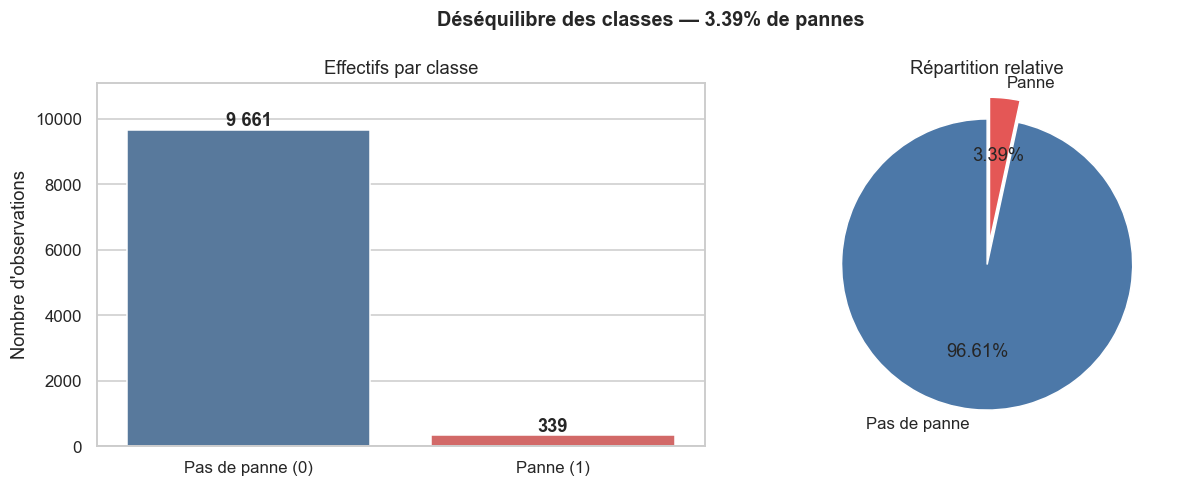

Ratio négatifs / positifs : 28.5 pour 1


In [9]:
counts = df[TARGET].value_counts().sort_index()
taux = df[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=["Pas de panne (0)", "Panne (1)"], y=counts.values, ax=axes[0],
            palette=["#4C78A8", "#E45756"], hue=["Pas de panne (0)", "Panne (1)"], legend=False)
axes[0].set_ylabel("Nombre d'observations")
axes[0].set_title("Effectifs par classe")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 120, f"{v:,}".replace(",", " "), ha="center", fontweight="bold")
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie([1 - taux, taux], labels=["Pas de panne", "Panne"], autopct="%1.2f%%",
            colors=["#4C78A8", "#E45756"], startangle=90, explode=(0, 0.15))
axes[1].set_title("Répartition relative")

fig.suptitle(f"Déséquilibre des classes — {taux:.2%} de pannes", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_desequilibre_classes.png", bbox_inches="tight")
plt.show()

print(f"Ratio négatifs / positifs : {(1 - taux) / taux:.1f} pour 1")

Le jeu de données compte **3,39 % de pannes**, soit environ 28 observations négatives pour une positive.

Conséquence directe sur l'évaluation : un classifieur qui prédirait systématiquement l'absence de panne atteindrait **96,6 % d'accuracy** sans détecter la moindre défaillance. L'accuracy est donc inexploitable ici. L'évaluation reposera sur la précision, le rappel, le F1-score et la PR-AUC — cette dernière étant préférée à la ROC-AUC, qui reste optimiste lorsque la classe négative domine largement.

## 4. Distribution des variables de fonctionnement

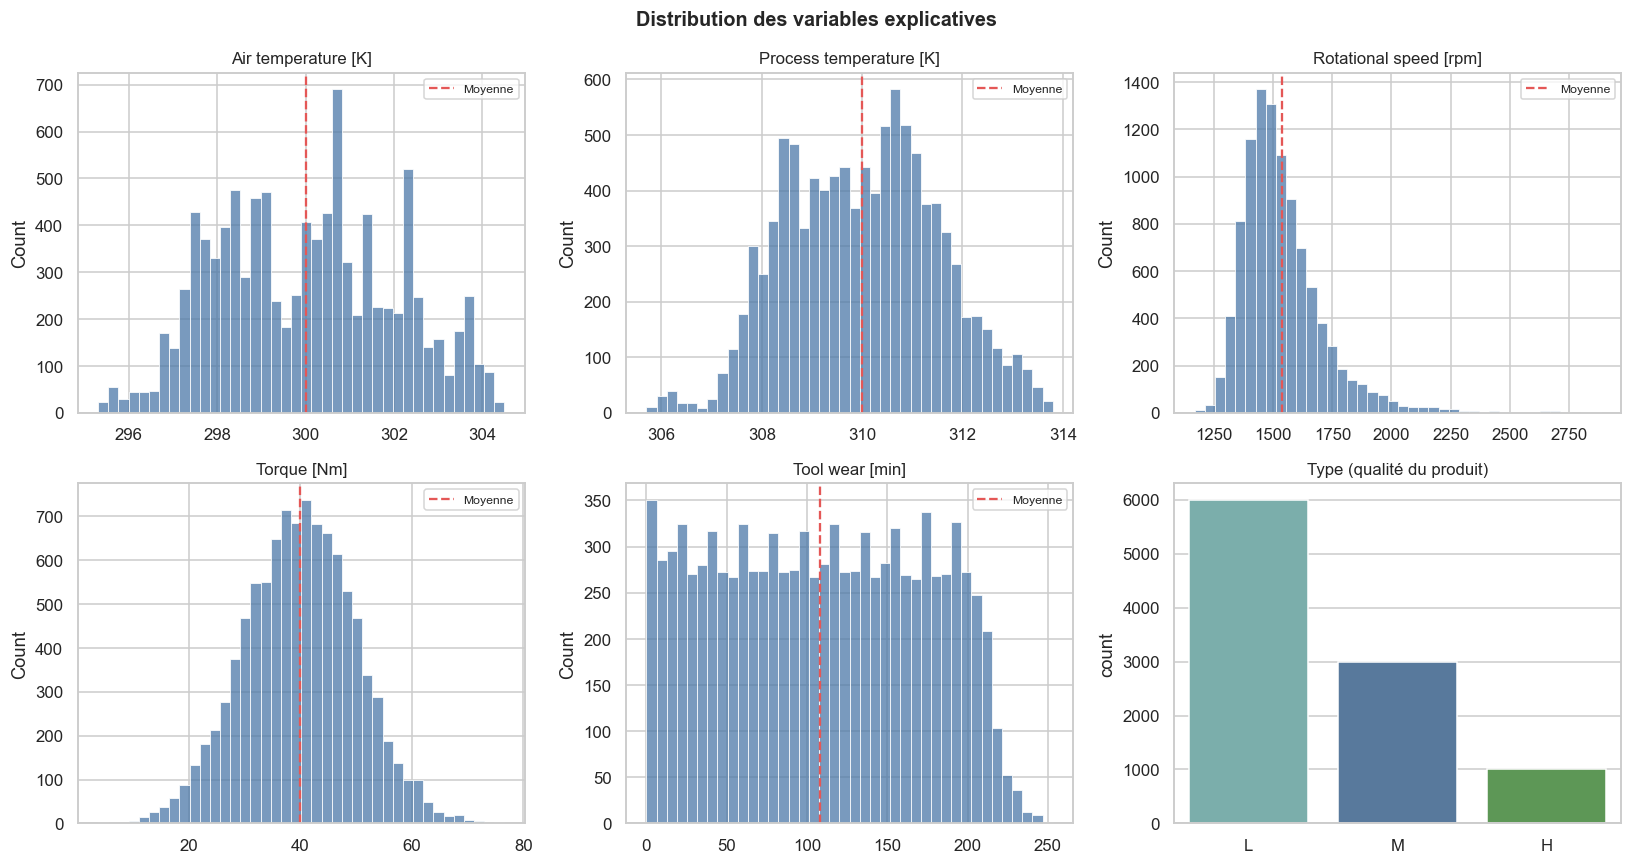

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C78A8", edgecolor="white", linewidth=0.5)
    ax.axvline(df[col].mean(), color="#E45756", linestyle="--", linewidth=1.5, label="Moyenne")
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.legend(fontsize=8)

sns.countplot(x="Type", data=df, order=["L", "M", "H"], ax=axes.flat[5],
              palette=["#4C78A8", "#72B7B2", "#54A24B"], hue="Type", legend=False)
axes.flat[5].set_title("Type (qualité du produit)", fontsize=11)
axes.flat[5].set_xlabel("")

fig.suptitle("Distribution des variables explicatives", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distributions.png", bbox_inches="tight")
plt.show()

In [11]:
print("Asymétrie (skewness) des variables continues :")
print(df[NUMERIC_FEATURES].skew().sort_values(ascending=False).round(3))

Asymétrie (skewness) des variables continues :
Rotational speed [rpm]     1.993
Air temperature [K]        0.114
Tool wear [min]            0.027
Process temperature [K]    0.015
Torque [Nm]               -0.010
dtype: float64


Les deux températures et le couple suivent des distributions approximativement normales. La vitesse de rotation est nettement asymétrique à droite, avec une queue de valeurs élevées. L'usure de l'outil est quasi uniforme sur l'intervalle 0–250 minutes, ce qui traduit un échantillonnage régulier du cycle de vie de l'outil plutôt qu'un phénomène aléatoire.

## 5. Distributions conditionnelles selon la survenue d'une panne

L'enjeu est d'identifier les variables qui séparent effectivement les deux classes.

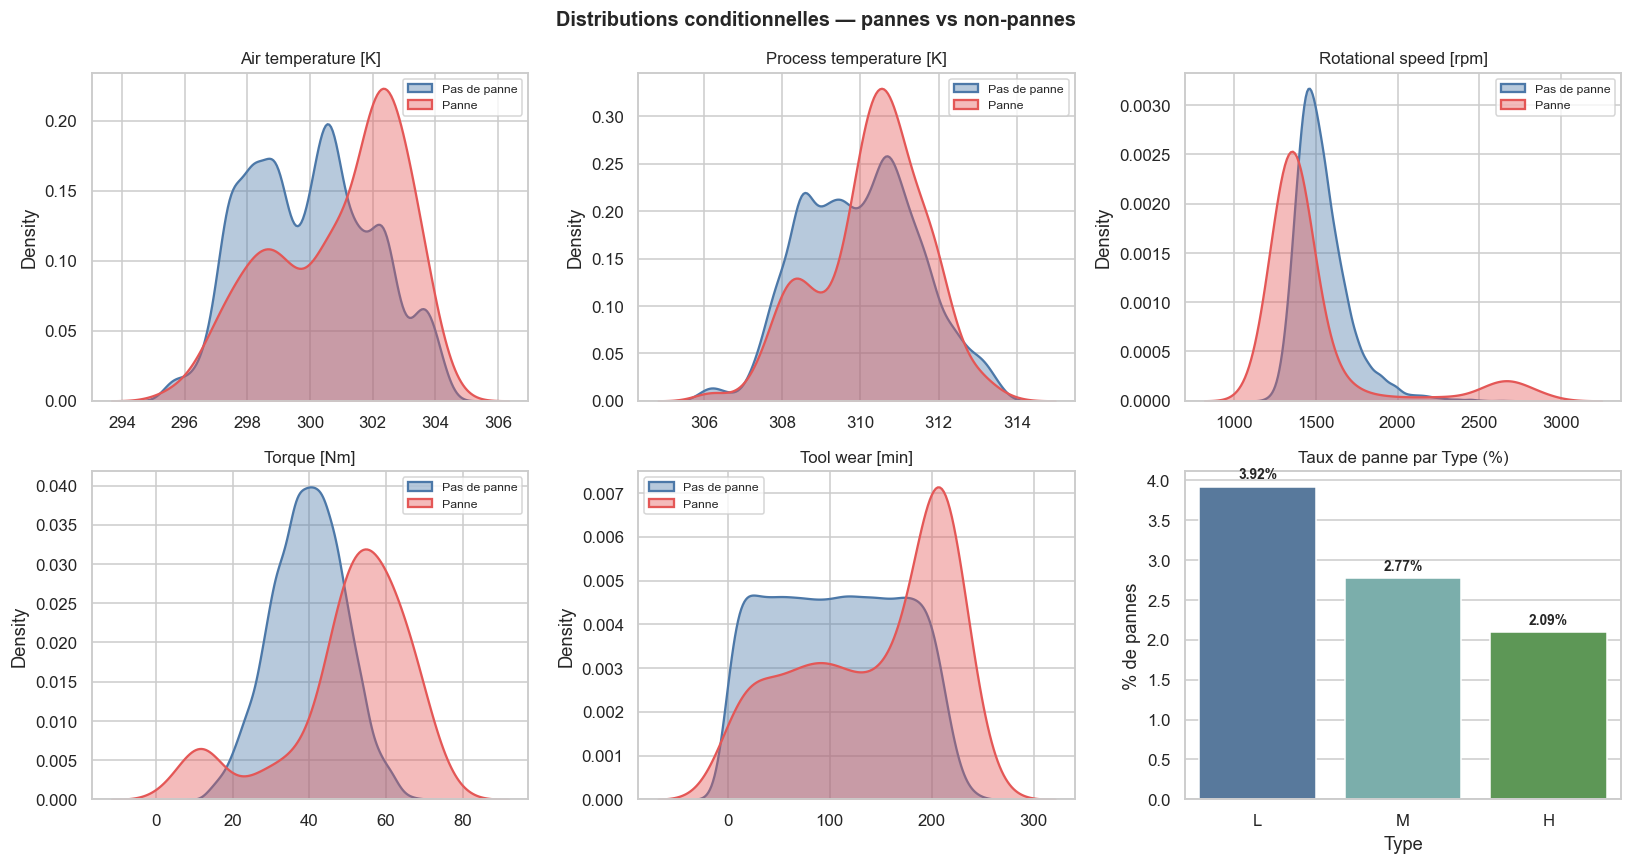

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
palette = {0: "#4C78A8", 1: "#E45756"}

for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    for cls in [0, 1]:
        sns.kdeplot(df.loc[df[TARGET] == cls, col], ax=ax, fill=True, alpha=0.4,
                    color=palette[cls], label="Panne" if cls else "Pas de panne",
                    common_norm=False, linewidth=1.5)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.legend(fontsize=8)

taux_par_type = df.groupby("Type")[TARGET].mean().reindex(["L", "M", "H"]) * 100
sns.barplot(x=taux_par_type.index, y=taux_par_type.values, ax=axes.flat[5],
            palette=["#4C78A8", "#72B7B2", "#54A24B"], hue=taux_par_type.index, legend=False)
axes.flat[5].set_title("Taux de panne par Type (%)", fontsize=11)
axes.flat[5].set_ylabel("% de pannes")
for i, v in enumerate(taux_par_type.values):
    axes.flat[5].text(i, v + 0.1, f"{v:.2f}%", ha="center", fontweight="bold", fontsize=9)

fig.suptitle("Distributions conditionnelles — pannes vs non-pannes", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_distributions_par_classe.png", bbox_inches="tight")
plt.show()

In [13]:
comparaison = df.groupby(TARGET)[NUMERIC_FEATURES].mean().T
comparaison.columns = ["Pas de panne", "Panne"]
comparaison["Écart relatif (%)"] = (
    (comparaison["Panne"] - comparaison["Pas de panne"]) / comparaison["Pas de panne"] * 100
)
comparaison.round(2)

,Pas de panne,Panne,Écart relatif (%)
Air temperature [K],299.97,300.89,0.30
Process temperature [K],310.00,310.29,0.10
Rotational speed [rpm],1540.26,1496.49,-2.84
Torque [Nm],39.63,50.17,26.59
Tool wear [min],106.69,143.78,34.76


Trois variables se détachent nettement :

- **Le couple** est en moyenne 27 % plus élevé sur les observations en panne. Sa distribution conditionnelle est bimodale : une masse principale dans les couples élevés (40–70 Nm) et un second groupe, plus restreint, dans les couples très faibles (moins de 15 Nm). Deux régimes de défaillance distincts coexistent donc — surcharge d'un côté, sous-charge de l'autre.
- **La vitesse de rotation** présente un profil miroir : le pic des pannes est décalé vers les valeurs basses (environ 1 350 rpm contre 1 450 rpm hors panne), avec en outre un second groupe de défaillances aux vitesses très élevées (au-delà de 2 500 rpm) absent de la classe négative. Couple et vitesse étant mécaniquement liés, ces deux régimes correspondent aux mêmes situations que la bimodalité du couple.
- **L'usure de l'outil** est en moyenne 35 % plus élevée avant une panne, ce qui correspond à l'intuition métier.

Les deux températures se recouvrent davantage entre les classes : prises isolément, elles discriminent peu.

Le taux de panne varie également selon la qualité du produit : les produits de qualité inférieure (`L`) tombent en panne plus souvent que les produits de qualité supérieure (`H`).

## 6. Corrélations

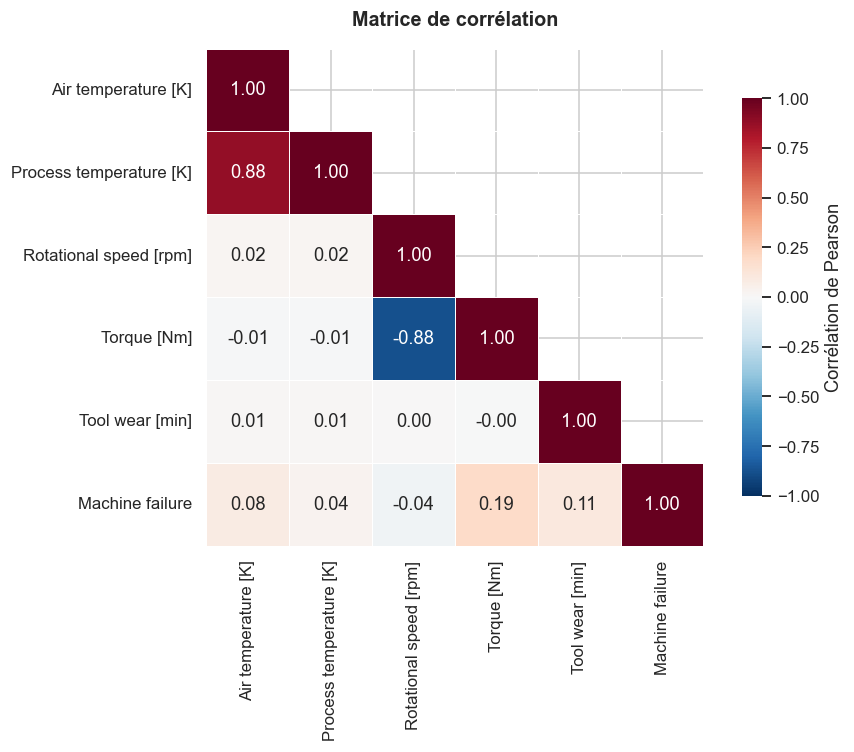

In [14]:
corr_df = df[NUMERIC_FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)
sns.heatmap(corr_df, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.8, "label": "Corrélation de Pearson"})
ax.set_title("Matrice de corrélation", fontsize=13, fontweight="bold", pad=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_correlations.png", bbox_inches="tight")
plt.show()

In [15]:
print("Corrélations avec la cible, par ordre décroissant de magnitude :")
print(corr_df[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

Corrélations avec la cible, par ordre décroissant de magnitude :
Torque [Nm]                0.191
Tool wear [min]            0.105
Air temperature [K]        0.083
Rotational speed [rpm]    -0.044
Process temperature [K]    0.036
Name: Machine failure, dtype: float64


Deux enseignements :

**Les deux températures sont fortement corrélées entre elles** (r ≈ 0,88). C'est attendu physiquement — la température du process suit celle de l'air ambiant. Cette redondance pénalise l'interprétation des coefficients d'une régression logistique (multicolinéarité) mais ne gêne pas les modèles à base d'arbres. Les deux variables sont conservées, la limite est signalée lors de l'interprétation de la baseline.

**Le couple et la vitesse de rotation sont fortement anticorrélés** (r ≈ -0,88), ce qui traduit la relation mécanique entre ces deux grandeurs à puissance donnée.

**Aucune variable prise isolément n'est fortement corrélée à la cible** : les corrélations linéaires restent faibles. Cela suggère que la survenue d'une panne dépend de *combinaisons* de conditions plutôt que du dépassement d'un seuil sur une variable unique — un argument en faveur des modèles non linéaires, qui sera testé au notebook de modélisation.

## 7. Valeurs atypiques

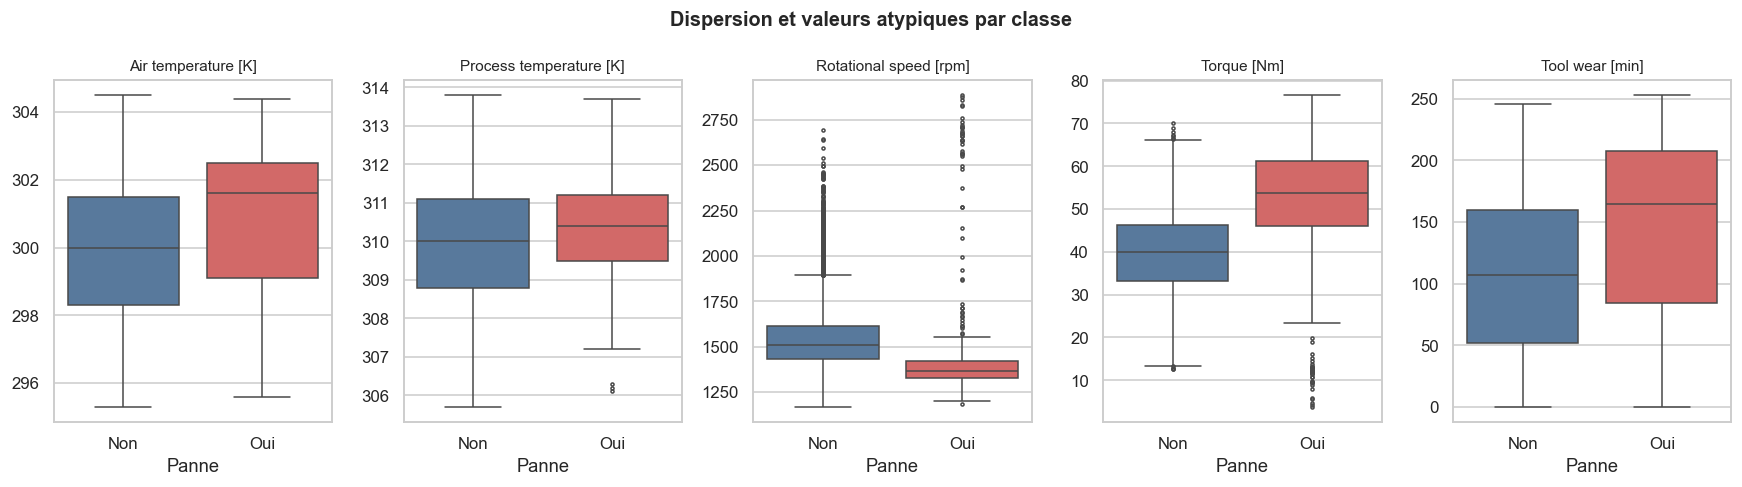

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))

for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, hue=TARGET,
                palette={0: "#4C78A8", 1: "#E45756"}, legend=False, fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Panne")
    ax.set_ylabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non", "Oui"])

fig.suptitle("Dispersion et valeurs atypiques par classe", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_boxplots.png", bbox_inches="tight")
plt.show()

In [17]:
def compte_atypiques(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    borne_bas, borne_haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < borne_bas) | (serie > borne_haut)).sum()

atypiques = pd.DataFrame({
    "Valeurs atypiques": [compte_atypiques(df[c]) for c in NUMERIC_FEATURES],
    "Part (%)": [compte_atypiques(df[c]) / len(df) * 100 for c in NUMERIC_FEATURES],
}, index=NUMERIC_FEATURES).round(2)

atypiques

,Valeurs atypiques,Part (%)
Air temperature [K],0,0.00
Process temperature [K],0,0.00
Rotational speed [rpm],418,4.18
Torque [Nm],69,0.69
Tool wear [min],0,0.00


Les valeurs atypiques se concentrent exclusivement sur la vitesse de rotation (418 points, 4,2 %) et le couple (69 points, 0,7 %). Les températures et l'usure de l'outil n'en comptent aucune au sens du critère de Tukey. Ces points extrêmes coïncident largement avec les observations en panne — ce sont précisément les régimes de fonctionnement limites qui provoquent les défaillances.

**Aucune valeur atypique n'est supprimée.** Ces points ne sont pas des erreurs de mesure mais le signal que les modèles doivent apprendre à reconnaître. Les écarter reviendrait à retirer une partie de la classe positive, déjà minoritaire.

## 8. Export du jeu de données préparé

In [18]:
df_model = df[FEATURES + [TARGET]].copy()
df_model.to_csv(PROCESSED_DIR / "ai4i2020_model.csv", index=False)

print("Fichier exporté :", PROCESSED_DIR / "ai4i2020_model.csv")
print("Dimensions :", df_model.shape)
df_model.head()

Fichier exporté : ../data/processed/ai4i2020_model.csv
Dimensions : (10000, 7)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## Conclusions de l'analyse exploratoire

**Qualité des données.** 10 000 observations, aucune valeur manquante, aucun doublon. Le nettoyage se limite à la sélection des variables.

**Variable cible.** `Machine failure`, avec 339 pannes sur 10 000 observations, soit 3,39 %. Le déséquilibre impose d'évaluer les modèles sur la précision, le rappel, le F1-score et la PR-AUC plutôt que sur l'accuracy.

**Variables écartées.** Les identifiants `UDI` et `Product ID`, sans contenu généralisable, ainsi que les cinq indicatrices de mode de défaillance, qui constituent une fuite de données puisqu'elles ne sont renseignées qu'après la panne.

**Variables retenues.** Six variables explicatives : `Type`, les deux températures, la vitesse de rotation, le couple et l'usure de l'outil.

**Signal disponible.** Le couple, la vitesse de rotation et l'usure de l'outil séparent visiblement les deux classes. Les corrélations linéaires avec la cible restent toutefois faibles, ce qui suggère que les pannes résultent de combinaisons de conditions plutôt que de seuils univariés.

**Hypothèse pour la modélisation.** Les modèles non linéaires (Random Forest, XGBoost) devraient mieux détecter les pannes que la régression logistique, au prix d'un nombre potentiellement plus élevé de faux positifs. Cette hypothèse est testée dans `02_modeling.ipynb`.

**Points de vigilance identifiés.**

- Forte colinéarité entre les deux températures (r ≈ 0,88) et entre couple et vitesse de rotation (r ≈ -0,88) : l'interprétation des coefficients de la régression logistique en sera affectée.
- Quelques observations présentent un mode de défaillance levé sans que la panne soit déclarée, principalement sur `RNF` (panne aléatoire, non prédictible par construction). Elles abaissent le plafond de performance atteignable.